# 02 - Student Performance Data Explorer (Mini Project)
**Task 1, Parts D, E and F**

**Problem:** institutions collect student performance data but rarely extract insights from it. This notebook loads, cleans and explores a student dataset and summarises the trends.

**Workflow:** Load -> Clean -> Analyse -> Visualise -> Insights

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_utils import missing_report, iqr_outliers, save_fig, clean_columns
sns.set_theme(style="whitegrid", palette="deep")
%matplotlib inline

## 1. Load the data (Part D)

In [2]:
df = pd.read_csv("../data/student_data.csv")
print("Shape:", df.shape)
df.head(10)

Shape: (509, 10)


,Student ID,Gender,Parental Education,Test Prep,Study Hours,Attendance %,Sleep Hours,Math Score,Reading Score,Writing Score
0,S1000,Male,Masters,Completed,3.4,97.0,6.9,100.0,95.0,94.0
1,S1001,Female,High School,Not Completed,1.8,91.8,6.2,60.0,61.0,66.0
2,S1002,Male,Bachelors,Not Completed,3.9,74.1,6.5,71.0,78.0,75.0
3,S1003,Male,High School,Not Completed,4.1,65.5,7.7,69.0,91.0,89.0
4,S1004,Female,Bachelors,Not Completed,0.7,49.4,7.0,67.0,49.0,65.0
5,S1005,Male,Bachelors,Completed,1.4,76.0,7.4,68.0,79.0,74.0
6,S1006,Female,High School,Not Completed,3.2,100.0,7.7,81.0,80.0,81.0
7,S1007,Male,Masters,Not Completed,2.6,86.8,6.6,73.0,82.0,77.0
8,S1008,Male,High School,Completed,3.0,75.8,7.8,73.0,89.0,83.0
9,S1009,Female,High School,Completed,2.0,87.1,7.4,NaN,83.0,88.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 509 entries, 0 to 508
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student ID          509 non-null    str    
 1   Gender              509 non-null    str    
 2   Parental Education  503 non-null    str    
 3   Test Prep           509 non-null    str    
 4   Study Hours         501 non-null    float64
 5   Attendance %        499 non-null    float64
 6   Sleep Hours         509 non-null    float64
 7   Math Score          497 non-null    float64
 8   Reading Score       509 non-null    float64
 9   Writing Score       509 non-null    float64
dtypes: float64(6), str(4)
memory usage: 39.9 KB


## 2. Explore columns

In [4]:
print(list(df.columns))
print()
print(df.dtypes)

['Student ID', 'Gender', 'Parental Education', 'Test Prep', 'Study Hours', 'Attendance %', 'Sleep Hours', 'Math Score', 'Reading Score', 'Writing Score']

Student ID                str
Gender                    str
Parental Education        str
Test Prep                 str
Study Hours           float64
Attendance %          float64
Sleep Hours           float64
Math Score            float64
Reading Score         float64
Writing Score         float64
dtype: object


## 3. Missing values

In [5]:
print("Total missing cells:", df.isnull().sum().sum())
missing_report(df)

Total missing cells: 36


,missing,percent
Math Score,12,2.36
Attendance %,10,1.96
Study Hours,8,1.57
Parental Education,6,1.18


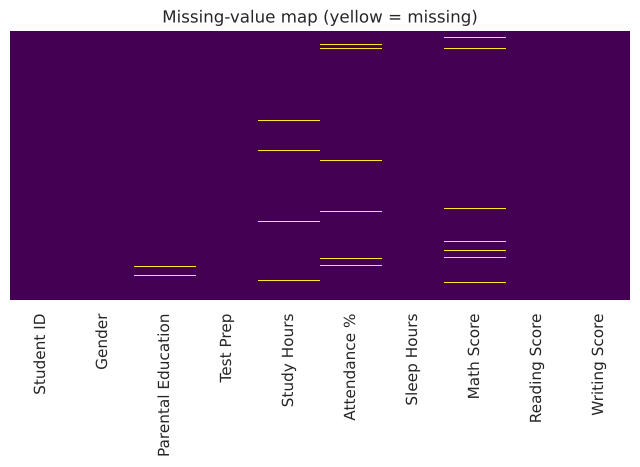

In [6]:
plt.figure(figsize=(8, 3.5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing-value map (yellow = missing)")
save_fig("student_missing_values.png"); plt.show()

## 4. Clean the data
Steps: remove duplicate rows, fill numeric gaps with the **median** (robust to outliers), fill categorical gaps with the **mode**, rename columns to snake_case.

In [7]:
print("Duplicate rows:", df.duplicated().sum())
clean = df.drop_duplicates().copy()

num_cols = clean.select_dtypes("number").columns
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
for c in clean.select_dtypes("object").columns.drop("Student ID"):
    clean[c] = clean[c].fillna(clean[c].mode()[0])

clean = clean_columns(clean)
print("Shape after cleaning:", clean.shape)
print("Remaining missing values:", clean.isnull().sum().sum())
clean.to_csv("../data/student_data_clean.csv", index=False)
clean.head()

Duplicate rows: 9
Shape after cleaning: (500, 10)
Remaining missing values: 0


,student_id,gender,parental_education,test_prep,study_hours,attendance,sleep_hours,math_score,reading_score,writing_score
0,S1000,Male,Masters,Completed,3.4,97.0,6.9,100.0,95.0,94.0
1,S1001,Female,High School,Not Completed,1.8,91.8,6.2,60.0,61.0,66.0
2,S1002,Male,Bachelors,Not Completed,3.9,74.1,6.5,71.0,78.0,75.0
3,S1003,Male,High School,Not Completed,4.1,65.5,7.7,69.0,91.0,89.0
4,S1004,Female,Bachelors,Not Completed,0.7,49.4,7.0,67.0,49.0,65.0


## 5. Statistical summary (Part E)

In [8]:
clean.describe().round(2)

,study_hours,attendance,sleep_hours,math_score,reading_score,writing_score
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,2.98,81.30,7.00,78.14,80.20,79.16
std,1.14,10.72,1.13,11.54,10.46,10.06
min,0.00,41.90,3.70,5.00,49.00,50.00
25%,2.20,74.10,6.30,72.00,73.00,72.00
50%,3.00,81.95,7.00,78.00,81.00,79.50
75%,3.70,88.43,7.70,85.00,87.00,87.00
max,6.50,100.00,10.00,100.00,100.00,100.00


In [9]:
scores = ["math_score", "reading_score", "writing_score"]
summary = pd.DataFrame({
    "mean": clean[scores].mean(),
    "median": clean[scores].median(),
    "mode": clean[scores].mode().iloc[0],
    "std": clean[scores].std(),
}).round(2)
summary

,mean,median,mode,std
math_score,78.14,78.0,79.0,11.54
reading_score,80.20,81.0,82.0,10.46
writing_score,79.16,79.5,83.0,10.06


## 6. Histograms

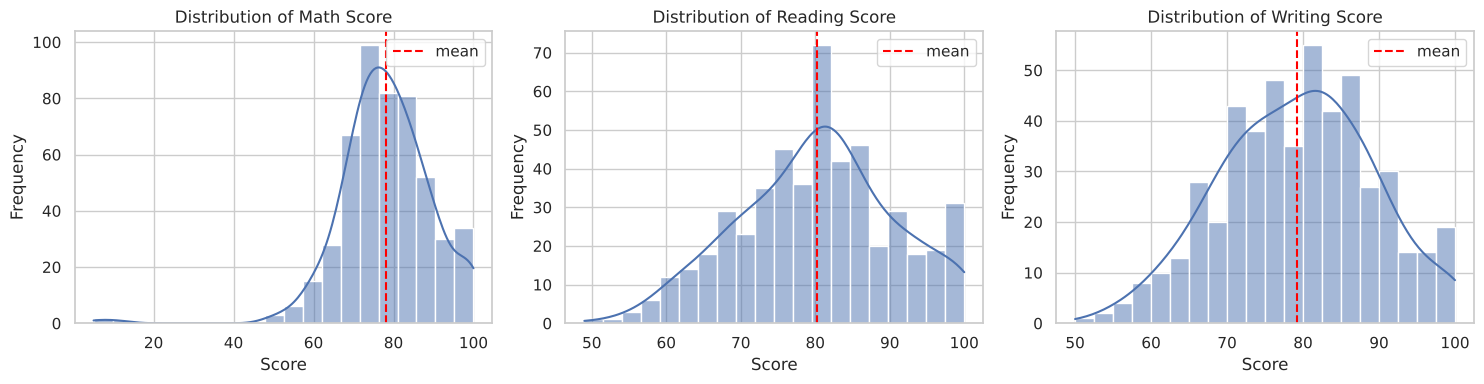

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, scores):
    sns.histplot(clean[col], bins=20, kde=True, ax=ax)
    ax.axvline(clean[col].mean(), color="red", ls="--", label="mean")
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel("Score"); ax.set_ylabel("Frequency"); ax.legend()
plt.tight_layout(); save_fig("student_histograms.png"); plt.show()

## 7. Box plots and outliers

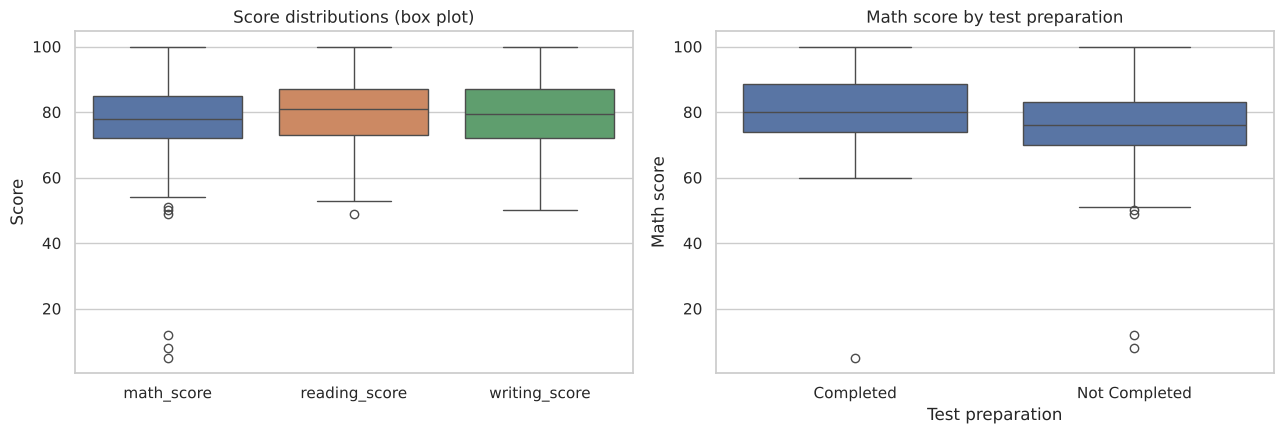

math_score: 6 outliers (IQR rule) -> [5, 8, 12, 49, 50, 51]
reading_score: 1 outliers (IQR rule) -> [49]
writing_score: 0 outliers (IQR rule) -> []


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=clean[scores], ax=axes[0])
axes[0].set_title("Score distributions (box plot)"); axes[0].set_ylabel("Score")
sns.boxplot(data=clean, x="test_prep", y="math_score", ax=axes[1])
axes[1].set_title("Math score by test preparation")
axes[1].set_xlabel("Test preparation"); axes[1].set_ylabel("Math score")
plt.tight_layout(); save_fig("student_boxplots.png"); plt.show()

for c in scores:
    o = iqr_outliers(clean[c])
    print(f"{c}: {len(o)} outliers (IQR rule) -> {sorted(o.astype(int).tolist())}")

## 8. Scatter plots

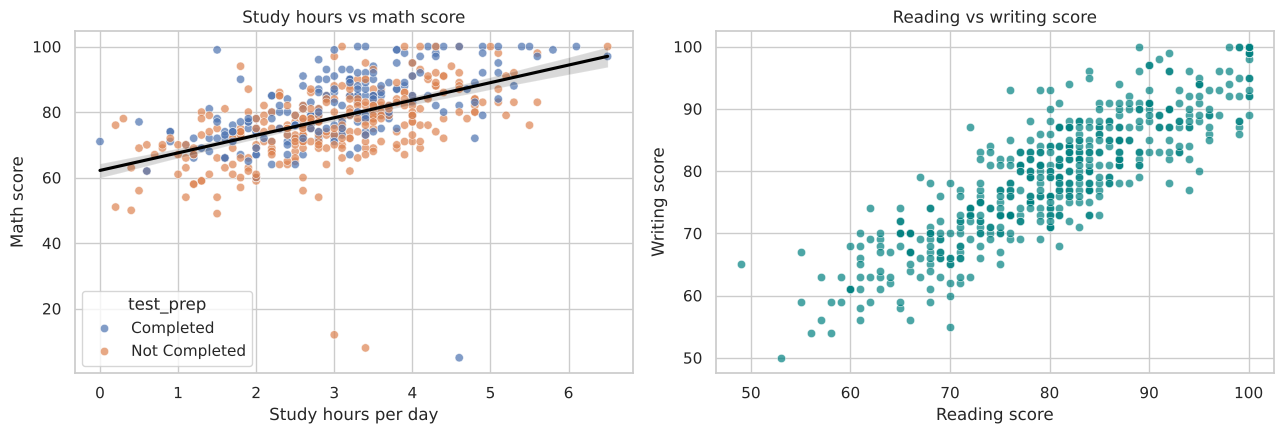

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=clean, x="study_hours", y="math_score", hue="test_prep", ax=axes[0], alpha=0.7)
sns.regplot(data=clean, x="study_hours", y="math_score", scatter=False, color="black", ax=axes[0])
axes[0].set_title("Study hours vs math score"); axes[0].set_xlabel("Study hours per day"); axes[0].set_ylabel("Math score")
sns.scatterplot(data=clean, x="reading_score", y="writing_score", ax=axes[1], alpha=0.7, color="teal")
axes[1].set_title("Reading vs writing score"); axes[1].set_xlabel("Reading score"); axes[1].set_ylabel("Writing score")
plt.tight_layout(); save_fig("student_scatter.png"); plt.show()

## 9. Correlation matrix and heatmap

In [13]:
corr = clean.select_dtypes("number").corr().round(2)
corr

,study_hours,attendance,sleep_hours,math_score,reading_score,writing_score
study_hours,1.00,-0.00,0.06,0.53,0.64,0.64
attendance,-0.00,1.00,-0.05,0.21,0.30,0.24
sleep_hours,0.06,-0.05,1.00,0.10,0.16,0.16
math_score,0.53,0.21,0.10,1.00,0.51,0.54
reading_score,0.64,0.30,0.16,0.51,1.00,0.86
writing_score,0.64,0.24,0.16,0.54,0.86,1.00


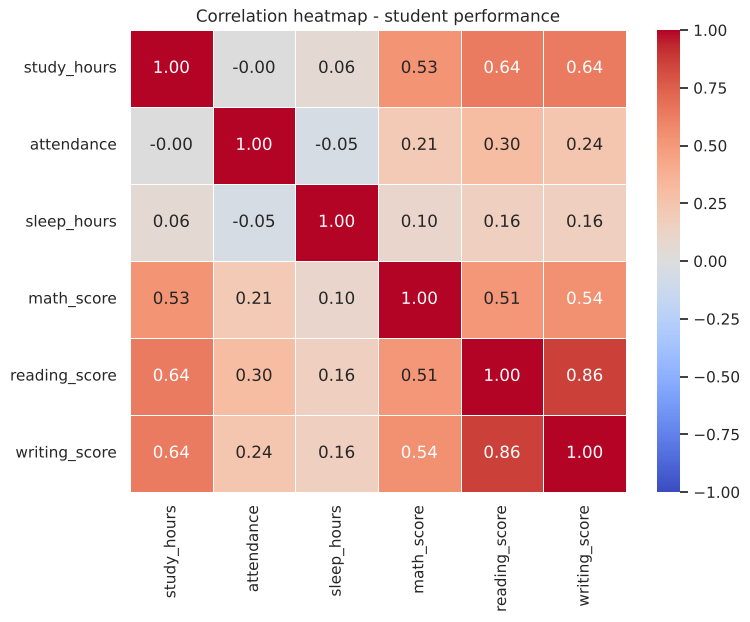

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title("Correlation heatmap - student performance")
save_fig("student_correlation_heatmap.png"); plt.show()

## 10. Group comparisons

In [15]:
print(clean.groupby("test_prep")[scores].mean().round(1), "\n")
print(clean.groupby("parental_education")[scores].mean().round(1).sort_values("math_score"), "\n")
print(clean.groupby("gender")[scores].mean().round(1))

               math_score  reading_score  writing_score
test_prep                                              
Completed            81.3           83.5           82.4
Not Completed        75.9           77.9           76.9 

                    math_score  reading_score  writing_score
parental_education                                          
High School               76.8           79.5           78.0
Bachelors                 78.1           80.1           79.2
Masters                   79.3           81.0           80.3
PhD                       81.7           81.9           81.5 

        math_score  reading_score  writing_score
gender                                          
Female        77.8           80.1           78.9
Male          78.5           80.3           79.4


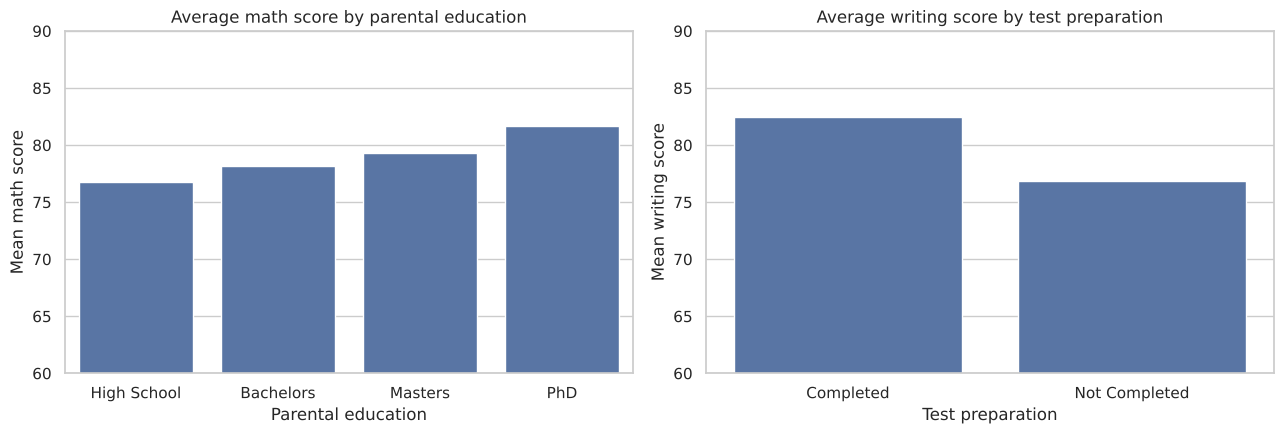

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=clean, x="parental_education", y="math_score",
            order=["High School", "Bachelors", "Masters", "PhD"], ax=axes[0], errorbar=None)
axes[0].set_title("Average math score by parental education")
axes[0].set_xlabel("Parental education"); axes[0].set_ylabel("Mean math score"); axes[0].set_ylim(60, 90)
sns.barplot(data=clean, x="test_prep", y="writing_score", ax=axes[1], errorbar=None)
axes[1].set_title("Average writing score by test preparation")
axes[1].set_xlabel("Test preparation"); axes[1].set_ylabel("Mean writing score"); axes[1].set_ylim(60, 90)
plt.tight_layout(); save_fig("student_group_bars.png"); plt.show()

## 11. Key insights (data-driven)

In [17]:
r = clean.select_dtypes("number").corr()
prep = clean.groupby("test_prep")["math_score"].mean()
print("1. Study hours is the strongest driver of marks: corr with math = %.2f, reading = %.2f." % (r.loc["study_hours", "math_score"], r.loc["study_hours", "reading_score"]))
print("2. Reading and writing scores move almost together (corr = %.2f)." % r.loc["reading_score", "writing_score"])
print("3. Attendance has a smaller but positive effect (corr with math = %.2f)." % r.loc["attendance", "math_score"])
print("4. Students who completed test prep average %.1f in math vs %.1f for those who did not (+%.1f)." % (prep["Completed"], prep["Not Completed"], prep["Completed"] - prep["Not Completed"]))
print("5. Gender gap in math is small: %s" % clean.groupby("gender")["math_score"].mean().round(1).to_dict())
print("6. Sleep hours show only a weak relationship with scores (corr with math = %.2f)." % r.loc["sleep_hours", "math_score"])

1. Study hours is the strongest driver of marks: corr with math = 0.53, reading = 0.64.
2. Reading and writing scores move almost together (corr = 0.86).
3. Attendance has a smaller but positive effect (corr with math = 0.21).
4. Students who completed test prep average 81.3 in math vs 75.9 for those who did not (+5.3).
5. Gender gap in math is small: {'Female': 77.8, 'Male': 78.5}
6. Sleep hours show only a weak relationship with scores (corr with math = 0.10).


### Conclusion
Study time and test preparation are the levers most strongly associated with performance, while attendance contributes modestly. The cleaned dataset is saved to `data/student_data_clean.csv` and is ready for the modelling work in Task 2.

*Note: the dataset is synthetic, generated by `src/generate_datasets.py` with a fixed seed, so results are reproducible. Correlation does not imply causation.*